# DSA 4020 Assignment 1 - Classifying Customer Complaint Tickets
Run top to bottom. `random_state=42` everywhere. The test file is used only in Q17.

In [ ]:
# Colab setup: install missing packages and download NLTK data (safe to re-run)
!pip install -q gensim nltk
import nltk
for p in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(p, quiet=True)


## Setup

In [1]:
import re, time, warnings, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)
from gensim.models import Word2Vec
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 200, "display.max_colwidth", 200)
sns.set_theme(style="whitegrid")
train = pd.read_csv("complaints_train.csv")
test = pd.read_csv("complaints_test_unlabelled.csv")
train = train.astype({"complaint_text": object, "category": object}); test = test.astype({"complaint_text": object})
CATS = sorted(train.category.unique())


## Q1

Number of tickets: 401
                   count  percent
category                         
mpesa_transaction    139     34.7
network_data          97     24.2
account_access        68     17.0
loan_credit           57     14.2
fraud_scam            40     10.0
Average ticket length (words): 36.1  (median 36, min 10, max 67)
category
account_access       35.5
fraud_scam           37.8
loan_credit          31.5
mpesa_transaction    37.7
network_data         36.5
Name: n_words, dtype: float64


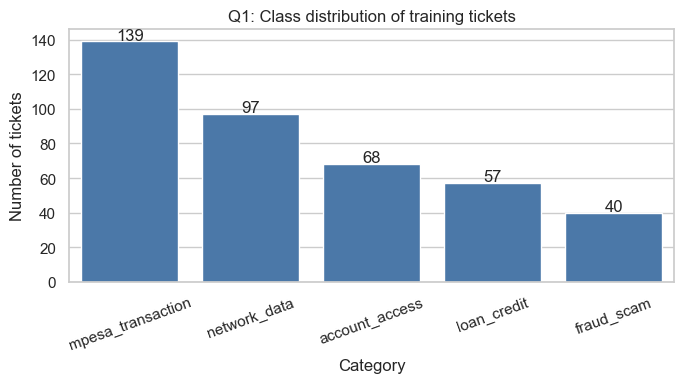

In [2]:
print("Number of tickets:", len(train))
dist = train.category.value_counts()
print(pd.DataFrame({"count": dist, "percent": (dist / len(train) * 100).round(1)}))
train["n_words"] = train.complaint_text.str.split().str.len()
print("Average ticket length (words): %.1f  (median %d, min %d, max %d)" % (
    train.n_words.mean(), train.n_words.median(), train.n_words.min(), train.n_words.max()))
print(train.groupby("category").n_words.mean().round(1))
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=dist.index, y=dist.values, ax=ax, color="#3b78b8")
for i, v in enumerate(dist.values): ax.text(i, v + 1, str(v), ha="center")
ax.set_title("Q1: Class distribution of training tickets"); ax.set_xlabel("Category"); ax.set_ylabel("Number of tickets")
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("fig_q1_class_dist.png", dpi=150); plt.show()


## Q2

In [3]:
for c in ["mpesa_transaction", "network_data", "fraud_scam"]:
    r = train[train.category == c].sample(1, random_state=SEED).iloc[0]
    print(f"[{c}] {r.ticket_id}: {r.complaint_text}\n")


[mpesa_transaction] T0394: The paybill payment for my electricity tokens has not been credited since on Friday. I sent KES 20,000 on Friday to the wrong number and need the transcation reversed. Someone is impersonating ur agent and collecting cash from customers.

[network_data] T0258: roaming charges appeared on my bill although i never left the country.

[fraud_scam] T0180: Agent withdrew cash from my account but the float was not updated and I got no SMS. Fuliza amount was deducted automatically when I deposited money, please explain.



## Q3

In [4]:
majority = dist.index[0]
print("Majority class:", majority)
print("Always-predict-majority accuracy: %.3f" % (train.category == majority).mean())
print("Always-predict-majority macro-F1: %.3f" % f1_score(train.category, [majority] * len(train), average="macro"))
print("Recall on fraud_scam for this model: 0.000")


Majority class: mpesa_transaction
Always-predict-majority accuracy: 0.347
Always-predict-majority macro-F1: 0.103
Recall on fraud_scam for this model: 0.000


## Q4 preprocessing

In [5]:
STOP = set(stopwords.words("english"))
stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()

def preprocess(text, remove_stop=False, stem=False, lemma=False):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)          # drop punctuation and numbers
    toks = word_tokenize(text)
    if remove_stop: toks = [t for t in toks if t not in STOP]
    if stem: toks = [stemmer.stem(t) for t in toks]
    if lemma: toks = [lemmatizer.lemmatize(t) for t in toks]
    return toks

SETTINGS = {
    "none": dict(),
    "stop words only": dict(remove_stop=True),
    "stop words + stemming": dict(remove_stop=True, stem=True),
    "stop words + lemmatisation": dict(remove_stop=True, lemma=True),
}
ex = train.loc[train.ticket_id == "T0001", "complaint_text"].iloc[0]
ex = "I paid the till number but the merchant says the payment did not reflect. Please reverse the KES 1,200 sent to a wrong paybill, I have been charged twice."
print("ORIGINAL:", ex)
for name, kw in SETTINGS.items():
    print(f"{name:28s}:", " ".join(preprocess(ex, **kw)))


ORIGINAL: I paid the till number but the merchant says the payment did not reflect. Please reverse the KES 1,200 sent to a wrong paybill, I have been charged twice.
none                        : i paid the till number but the merchant says the payment did not reflect please reverse the kes sent to a wrong paybill i have been charged twice
stop words only             : paid till number merchant says payment reflect please reverse kes sent wrong paybill charged twice
stop words + stemming       : paid till number merchant say payment reflect pleas revers ke sent wrong paybil charg twice


stop words + lemmatisation  : paid till number merchant say payment reflect please reverse kes sent wrong paybill charged twice


## Q5 vocabulary size

In [6]:
rows = []
for name, kw in SETTINGS.items():
    vocab = set(t for x in train.complaint_text for t in preprocess(x, **kw))
    rows.append((name, len(vocab)))
vt = pd.DataFrame(rows, columns=["setting", "vocabulary size"])
vt["change vs none"] = vt["vocabulary size"] - vt["vocabulary size"].iloc[0]
print(vt.to_string(index=False))
raw_vocab = set(t for x in train.complaint_text for t in x.split())
print("Raw whitespace-token vocab (no cleaning):", len(raw_vocab))


                   setting  vocabulary size  change vs none
                      none              357               0
           stop words only              304             -53
     stop words + stemming              280             -77
stop words + lemmatisation              295             -62
Raw whitespace-token vocab (no cleaning): 447


## Q6 code-switching

In [7]:
sw = ["nimeshindwa", "pesa", "mkopo", "nimesahau", "akaunti", "simu", "nimenunua", "tumetumiwa", "imefungwa", "kuelewa", "mtu", "hazijaingia", "nimelipa", "kutuma"]
from collections import Counter
cnt = Counter(t for x in train.complaint_text for t in preprocess(x))
found = [(w, cnt[w]) for w in sw if cnt[w] > 0]
print("Kiswahili/Sheng words found (word, frequency):", found)
print()
print(f"{'word':14s}{'stopword?':>10s}{'stem':>14s}{'lemma':>14s}")
for w, _ in found:
    print(f"{w:14s}{str(w in STOP):>10s}{stemmer.stem(w):>14s}{lemmatizer.lemmatize(w):>14s}")
# swahili words that are accidentally English stop words
sw_stop = ["na", "ya", "wa", "ni", "kwa", "mimi", "yangu", "hii", "sasa"]
print("\nShort Kiswahili function words that collide with English stop list:", [w for w in sw_stop if w in STOP])
# find top frequent non-english-looking tokens via nltk words? use simple heuristic: tokens never lemmatised/stemmed identically
swa_stop = ["na", "ya", "wa", "kwa", "ni", "yangu", "sana", "lakini", "kwamba", "hadi", "bado", "tafadhali"]
print("Kiswahili function words present in data:", [(w, cnt[w]) for w in swa_stop if cnt[w]])
# effect: proportion of tokens kept by English stop removal that are Swahili
sw_set = set(w for w, _ in found)
print("\nTop 40 tokens that survive English stop-word removal AND are not stems of common English:")
after = Counter(t for x in train.complaint_text for t in preprocess(x, remove_stop=True))
print(after.most_common(60))


Kiswahili/Sheng words found (word, frequency): [('nimeshindwa', 35), ('pesa', 92), ('mkopo', 14), ('nimesahau', 21), ('akaunti', 21), ('simu', 31), ('nimenunua', 18), ('imefungwa', 21), ('kuelewa', 35), ('mtu', 13), ('hazijaingia', 18), ('kutuma', 13)]

word           stopword?          stem         lemma
nimeshindwa        False   nimeshindwa   nimeshindwa
pesa               False          pesa          pesa
mkopo              False         mkopo         mkopo
nimesahau          False     nimesahau     nimesahau
akaunti            False       akaunti       akaunti
simu               False          simu          simu
nimenunua          False     nimenunua     nimenunua
imefungwa          False     imefungwa     imefungwa
kuelewa            False       kuelewa       kuelewa
mtu                False           mtu           mtu
hazijaingia        False   hazijaingia   hazijaingia
kutuma             False        kutuma        kutuma

Short Kiswahili function words that collide with English

## Q7 harmful step: stop words list contains 'not','no','nor' which carry signal; also numbers

In [8]:
print("Negations in NLTK stop list:", [w for w in ["not", "no", "nor", "didn", "wasn", "don", "haven", "hasn", "couldn"] if w in STOP])
tr_y = train.category.values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def cv_f1(model, X, y=tr_y):
    s = cross_validate(model, X, y, cv=skf, scoring="f1_macro")["test_score"]
    return s.mean(), s.std()
def run_pipeline(analyzer, model=None):
    pipe = Pipeline([("v", TfidfVectorizer(analyzer=analyzer, sublinear_tf=True)),
                     ("m", model or LogisticRegression(max_iter=2000, C=10, random_state=SEED))])
    s = cross_validate(pipe, train.complaint_text, tr_y, cv=skf, scoring="f1_macro")["test_score"]
    return s.mean(), s.std()
res = {}
res["raw (lowercase only, no preprocessing)"] = run_pipeline(lambda x: x.lower().split())
res["clean, keep stop words"] = run_pipeline(lambda x: preprocess(x))
res["clean + stop words removed (NLTK list)"] = run_pipeline(lambda x: preprocess(x, remove_stop=True))
res["clean + stemming (keep stop words)"] = run_pipeline(lambda x: preprocess(x, stem=True))
res["clean + stop + stemming"] = run_pipeline(lambda x: preprocess(x, remove_stop=True, stem=True))
res["clean + stop + lemma"] = run_pipeline(lambda x: preprocess(x, remove_stop=True, lemma=True))
res["clean, digits kept (amounts/ids)"] = run_pipeline(lambda x: re.findall(r"[a-z0-9]+", x.lower()))
q7 = pd.DataFrame(res, index=["macro-F1 mean", "std"]).T.round(4)
print(q7)


Negations in NLTK stop list: ['not', 'no', 'nor', 'didn', 'wasn', 'don', 'haven', 'hasn', 'couldn']


                                        macro-F1 mean     std
raw (lowercase only, no preprocessing)         0.9091  0.0319
clean, keep stop words                         0.9094  0.0315
clean + stop words removed (NLTK list)         0.9009  0.0345
clean + stemming (keep stop words)             0.9078  0.0326
clean + stop + stemming                        0.9009  0.0345
clean + stop + lemma                           0.9009  0.0345
clean, digits kept (amounts/ids)               0.9071  0.0302


## Q8 BoW and TF-IDF

In [9]:
tok = lambda x: preprocess(x, remove_stop=True, lemma=True)
bow = CountVectorizer(analyzer=tok); Xb = bow.fit_transform(train.complaint_text)
tfidf = TfidfVectorizer(analyzer=tok, sublinear_tf=True); Xt = tfidf.fit_transform(train.complaint_text)
for n, X in [("Bag-of-Words", Xb), ("TF-IDF", Xt)]:
    sp = 1 - X.nnz / (X.shape[0] * X.shape[1])
    print(f"{n}: shape={X.shape}, non-zeros={X.nnz}, sparsity={sp:.4f} ({sp*100:.2f}% zeros)")
terms = np.array(tfidf.get_feature_names_out())
for c in CATS:
    m = np.asarray(Xt[(train.category == c).values].mean(axis=0)).ravel()
    print(f"{c:18s}", list(terms[np.argsort(-m)[:5]]))


Bag-of-Words: shape=(401, 295), non-zeros=8284, sparsity=0.9300 (93.00% zeros)
TF-IDF: shape=(401, 295), non-zeros=8284, sparsity=0.9300 (93.00% zeros)
account_access     ['pin', 'app', 'account', 'phone', 'update']
fraud_scam         ['someone', 'customer', 'link', 'fake', 'impersonating']
loan_credit        ['loan', 'still', 'repaid', 'outstanding', 'full']
mpesa_transaction  ['transaction', 'paybill', 'pesa', 'kes', 'payment']
network_data       ['bundle', 'keep', 'hour', 'network', 'call']


## Q9 unigram vs bigram

In [10]:
def tfv(ngram): return TfidfVectorizer(analyzer="word", tokenizer=tok, preprocessor=lambda x: x, token_pattern=None, lowercase=False, ngram_range=ngram, sublinear_tf=True) if False else None
class NG:
    pass
uni = Pipeline([("v", TfidfVectorizer(preprocessor=lambda x: " ".join(tok(x)), ngram_range=(1, 1), sublinear_tf=True)), ("m", LogisticRegression(max_iter=2000, C=10, random_state=SEED))])
bi = Pipeline([("v", TfidfVectorizer(preprocessor=lambda x: " ".join(tok(x)), ngram_range=(1, 2), sublinear_tf=True)), ("m", LogisticRegression(max_iter=2000, C=10, random_state=SEED))])
for n, p in [("unigrams", uni), ("unigrams+bigrams", bi)]:
    s = cross_validate(p, train.complaint_text, tr_y, cv=skf, scoring="f1_macro")["test_score"]
    print(f"{n:18s} macro-F1 = {s.mean():.4f} +/- {s.std():.4f}")
v2 = TfidfVectorizer(preprocessor=lambda x: " ".join(tok(x)), ngram_range=(1, 2), sublinear_tf=True)
X2 = v2.fit_transform(train.complaint_text)
print("matrix shape uni+bi:", X2.shape)
lr = LogisticRegression(max_iter=2000, C=10, random_state=SEED).fit(X2, tr_y)
names = np.array(v2.get_feature_names_out())
for i, c in enumerate(lr.classes_):
    idx = [j for j in np.argsort(-lr.coef_[i]) if " " in names[j]][:4]
    print(f"{c:18s} top bigrams:", [names[j] for j in idx])
df_ = np.asarray((X2 > 0).sum(axis=0)).ravel()
for bg in ["link text", "sim swap", "fake paybill", "wrong number", "pretending customer", "credit bureau"]:
    if bg in names:
        j = list(names).index(bg)
        sub = train[np.asarray(X2[:, j].todense()).ravel() > 0].category.value_counts().to_dict()
        print("bigram", repr(bg), "-> categories:", sub)
for u in ["link", "pretending", "swap", "fake", "text"]:
    sub = train[train.complaint_text.str.lower().str.contains(r"\b" + u + r"\b")].category.value_counts().to_dict()
    print("unigram", repr(u), "-> categories:", sub)


unigrams           macro-F1 = 0.8980 +/- 0.0364


unigrams+bigrams   macro-F1 = 0.9107 +/- 0.0238
matrix shape uni+bi: (401, 1422)
account_access     top bigrams: ['link transaction', 'name spelt', 'table keep', 'kes transaction']
fraud_scam         top bigrams: ['sm fuliza', 'link text', 'wallet balance', 'text wallet']
loan_credit        top bigrams: ['interest mobile', 'higher disclosed', 'loan look', 'look higher']
mpesa_transaction  top bigrams: ['code internet', 'evening internet', 'token credited', 'electricity token']
network_data       top bigrams: ['office technician', 'network office', 'technician come', 'otp code']
bigram 'link text' -> categories: {'fraud_scam': 12, 'mpesa_transaction': 3, 'account_access': 2}
bigram 'sim swap' -> categories: {'account_access': 7, 'mpesa_transaction': 7, 'network_data': 3, 'loan_credit': 1}
bigram 'fake paybill' -> categories: {'fraud_scam': 7, 'mpesa_transaction': 6}
bigram 'wrong number' -> categories: {'mpesa_transaction': 21, 'network_data': 2, 'loan_credit': 1}
bigram 'pretending cus

## Q10 Word2Vec

In [11]:
sent = [preprocess(x) for x in train.complaint_text]
w2v = Word2Vec(sent, vector_size=50, window=5, min_count=2, sg=1, epochs=100, seed=SEED, workers=1)
print("W2V vocab size:", len(w2v.wv), " corpus tokens:", sum(map(len, sent)))
for w in ["loan", "pin", "network"]:
    print(w, "->", [(a, round(b, 2)) for a, b in w2v.wv.most_similar(w, topn=5)])
for w in ["paybill", "otp"]:
    if w in w2v.wv: print(w, "->", [(a, round(b, 2)) for a, b in w2v.wv.most_similar(w, topn=5)])
def doc_vec(toks, kv=w2v.wv):
    v = [kv[t] for t in toks if t in kv]
    return np.mean(v, axis=0) if v else np.zeros(kv.vector_size)
Xw_all = np.vstack([doc_vec(t) for t in sent])
print("Document matrix:", Xw_all.shape)
# averaging loses order: same vector for permuted tickets
a = ["wrong", "paybill", "payment", "reversed"]; b = ["reversed", "payment", "paybill", "wrong"]
print("Identical average vectors for reordered words:", np.allclose(doc_vec(a), doc_vec(b)))
# GloVe not available offline


W2V vocab size: 357  corpus tokens: 14500
loan -> [('disbursement', 0.51), ('still', 0.51), ('disclosed', 0.51), ('what', 0.5), ('outstanding', 0.49)]
pin -> [('asked', 0.58), ('blocked', 0.56), ('akaunti', 0.54), ('nimesahau', 0.53), ('imefungwa', 0.49)]
network -> [('coverage', 0.74), ('down', 0.7), ('area', 0.63), ('there', 0.62), ('g', 0.6)]
paybill -> [('electricity', 0.59), ('sent', 0.59), ('scammers', 0.56), ('using', 0.56), ('report', 0.56)]
otp -> [('arrives', 0.77), ('so', 0.69), ('miss', 0.65), ('codes', 0.65), ('hours', 0.61)]
Document matrix: (401, 50)
Identical average vectors for reordered words: True


## Q11 model comparison (5-fold stratified CV, training data only)

In [12]:
# NOTE: Word2Vec is re-trained inside each fold (no leakage from validation fold)
from sklearn.base import BaseEstimator, TransformerMixin
class W2VAvg(BaseEstimator, TransformerMixin):
    def __init__(self, dim=50): self.dim = dim
    def fit(self, X, y=None):
        s = [preprocess(x) for x in X]
        self.m_ = Word2Vec(s, vector_size=self.dim, window=5, min_count=2, sg=1, epochs=100, seed=SEED, workers=1)
        return self
    def transform(self, X): return np.vstack([doc_vec(preprocess(x), self.m_.wv) for x in X])
def tfidf_vec(ng=(1, 1)): return TfidfVectorizer(preprocessor=lambda x: " ".join(tok(x)), ngram_range=ng, sublinear_tf=True)
models = {
    "TF-IDF + MultinomialNB": Pipeline([("v", tfidf_vec()), ("m", MultinomialNB(alpha=0.1))]),
    "TF-IDF + LogisticRegression": Pipeline([("v", tfidf_vec()), ("m", LogisticRegression(max_iter=2000, C=10, random_state=SEED))]),
    "TF-IDF + LinearSVC": Pipeline([("v", tfidf_vec()), ("m", LinearSVC(C=1, random_state=SEED))]),
    "TF-IDF(1-2gram) + LinearSVC": Pipeline([("v", tfidf_vec((1, 2))), ("m", LinearSVC(C=1, random_state=SEED))]),
    "Word2Vec-avg + LogisticRegression": Pipeline([("v", W2VAvg()), ("m", LogisticRegression(max_iter=2000, C=10, random_state=SEED))]),
}
rows, fold_scores = [], {}
for n, p in models.items():
    t0 = time.time()
    cvr = cross_validate(p, train.complaint_text, tr_y, cv=skf, scoring=["f1_macro", "accuracy"])
    fold_scores[n] = cvr["test_f1_macro"]
    rows.append((n, cvr["test_f1_macro"].mean(), cvr["test_f1_macro"].std(), cvr["test_accuracy"].mean(), time.time() - t0))
q11 = pd.DataFrame(rows, columns=["model", "macro-F1 mean", "macro-F1 std", "accuracy mean", "CV time (s)"]).round(4)
print(q11.to_string(index=False))


                            model  macro-F1 mean  macro-F1 std  accuracy mean  CV time (s)
           TF-IDF + MultinomialNB         0.9073        0.0247         0.9202       0.3822
      TF-IDF + LogisticRegression         0.8980        0.0364         0.9076       0.4407
               TF-IDF + LinearSVC         0.9132        0.0344         0.9226       0.3761
      TF-IDF(1-2gram) + LinearSVC         0.9215        0.0312         0.9301       0.4029
Word2Vec-avg + LogisticRegression         0.8934        0.0500         0.9051      12.8930


## Q12 controlled experiment: class_weight balanced (only change)

In [13]:
def lrp(cw): return Pipeline([("v", tfidf_vec()), ("m", LogisticRegression(max_iter=2000, C=10, class_weight=cw, random_state=SEED))])
rep = []
for seed in [42, 1, 2, 3, 4]:
    k = StratifiedKFold(5, shuffle=True, random_state=seed)
    a_ = cross_validate(lrp(None), train.complaint_text, tr_y, cv=k, scoring="f1_macro")["test_score"]
    b_ = cross_validate(lrp("balanced"), train.complaint_text, tr_y, cv=k, scoring="f1_macro")["test_score"]
    rep.append((seed, a_.mean(), b_.mean(), a_, b_))
a_f = rep[0][3]; b_f = rep[0][4]
print("Seed 42 folds, class_weight=None    :", a_f.round(3), "mean %.4f std %.4f" % (a_f.mean(), a_f.std()))
print("Seed 42 folds, class_weight=balanced:", b_f.round(3), "mean %.4f std %.4f" % (b_f.mean(), b_f.std()))
d = b_f - a_f
print("Paired fold differences:", d.round(3), "mean diff %.4f, std of diff %.4f" % (d.mean(), d.std()))
print("Repeated CV (5 different shuffles): mean None=%.4f, balanced=%.4f" % (np.mean([r[1] for r in rep]), np.mean([r[2] for r in rep])))
alla = np.concatenate([r[3] for r in rep]); allb = np.concatenate([r[4] for r in rep])
print("All 25 folds: None %.4f +/- %.4f ; balanced %.4f +/- %.4f ; mean paired diff %.4f, SE %.4f" % (
    alla.mean(), alla.std(), allb.mean(), allb.std(), (allb - alla).mean(), (allb - alla).std(ddof=1) / np.sqrt(25)))
# Also the stop-word experiment


Seed 42 folds, class_weight=None    : [0.966 0.905 0.867 0.87  0.882] mean 0.8980 std 0.0364
Seed 42 folds, class_weight=balanced: [0.95  0.905 0.851 0.893 0.904] mean 0.9007 std 0.0316
Paired fold differences: [-0.016  0.    -0.016  0.023  0.022] mean diff 0.0027, std of diff 0.0172
Repeated CV (5 different shuffles): mean None=0.8963, balanced=0.8958
All 25 folds: None 0.8963 +/- 0.0411 ; balanced 0.8958 +/- 0.0362 ; mean paired diff -0.0004, SE 0.0048


## Q13/14 hold-out

In [14]:
final = Pipeline([("v", tfidf_vec((1, 2))), ("m", LinearSVC(C=1, class_weight="balanced", random_state=SEED))])
X_tr, X_va, y_tr, y_va = train_test_split(train.complaint_text, train.category, test_size=0.2, stratify=train.category, random_state=SEED)
t0 = time.time(); final.fit(X_tr, y_tr); fit_time = time.time() - t0
pred = final.predict(X_va)
p, r, f, _ = precision_recall_fscore_support(y_va, pred, average="macro")
print("Train size %d, validation size %d, fit time %.3fs" % (len(X_tr), len(X_va), fit_time))
print("Accuracy        : %.4f" % accuracy_score(y_va, pred))
print("Macro precision : %.4f" % p); print("Macro recall    : %.4f" % r); print("Macro F1        : %.4f" % f)
print("Weighted F1     : %.4f" % f1_score(y_va, pred, average="weighted"))
print(classification_report(y_va, pred, digits=3))


Train size 320, validation size 81, fit time 0.069s
Accuracy        : 0.9136
Macro precision : 0.8993
Macro recall    : 0.8829
Macro F1        : 0.8900
Weighted F1     : 0.9113
                   precision    recall  f1-score   support

   account_access      0.769     0.714     0.741        14
       fraud_scam      0.857     0.750     0.800         8
      loan_credit      1.000     1.000     1.000        11
mpesa_transaction      0.966     1.000     0.982        28
     network_data      0.905     0.950     0.927        20

         accuracy                          0.914        81
        macro avg      0.899     0.883     0.890        81
     weighted avg      0.911     0.914     0.911        81



## Q15 confusion matrix

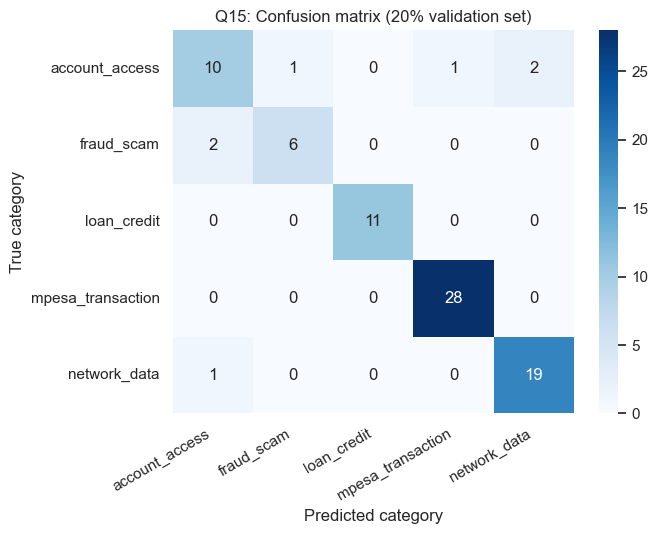

                   account_access  fraud_scam  loan_credit  mpesa_transaction  network_data
account_access                 10           1            0                  1             2
fraud_scam                      2           6            0                  0             0
loan_credit                     0           0           11                  0             0
mpesa_transaction               0           0            0                 28             0
network_data                    1           0            0                  0            19
Largest confusions (true, predicted, n): [('account_access', 'network_data', np.int64(2)), ('fraud_scam', 'account_access', np.int64(2)), ('account_access', 'fraud_scam', np.int64(1)), ('account_access', 'mpesa_transaction', np.int64(1)), ('network_data', 'account_access', np.int64(1))]
264 TRUE: network_data PRED: account_access | This is very frustrating, I have called customer care three times. The 4G network is down at our office and techni

5-fold CV (all 400): fraud_scam precision 0.875 recall 0.875 support 40
5-fold CV overall macro-F1 0.9158 accuracy 0.9252
                   account_access  fraud_scam  loan_credit  mpesa_transaction  network_data
account_access                 55           3            2                  4             4
fraud_scam                      2          35            0                  3             0
loan_credit                     1           0           56                  0             0
mpesa_transaction               2           2            0                133             2
network_data                    3           0            0                  2            92


In [15]:
cm = confusion_matrix(y_va, pred, labels=CATS)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATS, yticklabels=CATS, ax=ax)
ax.set_xlabel("Predicted category"); ax.set_ylabel("True category"); ax.set_title("Q15: Confusion matrix (20% validation set)")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig("fig_q15_confusion.png", dpi=150); plt.show()
print(pd.DataFrame(cm, index=CATS, columns=CATS).to_string())
off = [(CATS[i], CATS[j], cm[i, j]) for i in range(5) for j in range(5) if i != j and cm[i, j] > 0]
print("Largest confusions (true, predicted, n):", sorted(off, key=lambda x: -x[2])[:5])
wrong = X_va[pred != y_va.values]
for i in wrong.index[:4]:
    print(i, "TRUE:", y_va[i], "PRED:", pred[list(X_va.index).index(i)], "|", train.complaint_text[i])
# Q16
pf = precision_recall_fscore_support(y_va, pred, labels=["fraud_scam"])
print("fraud_scam precision %.3f recall %.3f f1 %.3f support %d" % (pf[0][0], pf[1][0], pf[2][0], pf[3][0]))
# CV-based fraud recall (more stable than 8 tickets)
from sklearn.model_selection import cross_val_predict
cvp = cross_val_predict(final, train.complaint_text, tr_y, cv=skf)
pf2 = precision_recall_fscore_support(tr_y, cvp, labels=["fraud_scam"])
print("5-fold CV (all 400): fraud_scam precision %.3f recall %.3f support %d" % (pf2[0][0], pf2[1][0], pf2[3][0]))
print("5-fold CV overall macro-F1 %.4f accuracy %.4f" % (f1_score(tr_y, cvp, average="macro"), accuracy_score(tr_y, cvp)))
print(pd.DataFrame(confusion_matrix(tr_y, cvp, labels=CATS), index=CATS, columns=CATS).to_string())


## Q17 final predictions

In [16]:
final.fit(train.complaint_text, train.category)
test["category"] = final.predict(test.complaint_text)
test[["ticket_id", "category"]].to_csv("predictions.csv", index=False)
chk = pd.read_csv("predictions.csv")
print(chk.shape, list(chk.columns), "all ids match:", set(chk.ticket_id) == set(test.ticket_id))
print(chk.head(10).to_string(index=False))
print(chk.category.value_counts())
# confidence: margin of decision function
dfun = final.decision_function(test.complaint_text)
srt = np.sort(dfun, axis=1); margin = srt[:, -1] - srt[:, -2]
print("Test tickets with small margin (<0.3) -> human review:", int((margin < 0.3).sum()), "of", len(test))


(99, 2) ['ticket_id', 'category'] all ids match: True
ticket_id          category
    X0001    account_access
    X0002      network_data
    X0003        fraud_scam
    X0004      network_data
    X0005        fraud_scam
    X0006       loan_credit
    X0007        fraud_scam
    X0008       loan_credit
    X0009 mpesa_transaction
    X0010       loan_credit
category
mpesa_transaction    32
network_data         24
account_access       18
loan_credit          16
fraud_scam            9
Name: count, dtype: int64
Test tickets with small margin (<0.3) -> human review: 10 of 99
